# 보고서 자동화 하네스 비교 실험

## 1. 프로젝트 개요와 연구 질문
우리 프로그램은 Python 소스·실행 기록을 근거로 보고서를 작성한다.
**같은 모델에서 한 번에 작성하는 방식과 역할을 나눠 작성하는 방식은 어떤 차이가 있는가?**

이 노트북은 실제 저장된 호출 기록을 분석한다. 기존 프로그램은 `.py`로 구현했으며,
제출용 `.ipynb`에는 실험 방법·실행 연결·결과표·그래프·해석을 담았다.


제출용 사본: 실제 과거 결과를 노트북 안에 포함했습니다. 새 모델 호출 없이 재실행할 수 있습니다. 조건별 반복은 1회이며, 현재 로컬 모델 간 성능 비교와 구분합니다.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# 현재 폴더 또는 제출 폴더 루트에서 실행할 수 있습니다.
candidates = [Path('report_comparison.ipynb'), Path('notebooks/report_comparison.ipynb')]
notebook_path = next(path for path in candidates if path.exists())
snapshot = json.loads(notebook_path.read_text(encoding='utf-8'))['metadata']['comparison_snapshot']
print('과거 클라우드 호출 구조 실험: 저장된 기록만 확인합니다.')

과거 클라우드 호출 구조 실험: 저장된 기록만 확인합니다.


## 3. 입력 자료와 전처리
개인 업로드·비밀 설정을 제외하고 우리 프로그램의 지정된 코드 4개에서 앞부분을 3,000자씩 추출했다.
비밀정보 패턴을 가리고 근거 ID를 붙였다. 이는 **전체 코드 검토가 아닌 제한된 코드 자료 실험**이다.
각 조건의 시작 자료와 보고서 작성 기준은 같으며, 팀 조건에서는 중간 산출물이 추가된다.
모델은 업로드 코드를 실행하지 않는다. 비교 실험용 Python 코드가 모델을 호출한다.


In [2]:
# 실제 사용한 자료와 설정을 확인합니다.
protocol = snapshot['protocol']
manifest = snapshot['manifest']
sources = pd.DataFrame([{"id": s["id"], "file": s["path"],
                         "characters": len(s["text"]), "truncated": s["truncated"]}
                        for s in manifest["sources"]])
print(sources.to_string(index=False))
print("모델:", protocol["model"], " / 반복 수:", protocol["repeats"])
print("자료 해시:", protocol["evidence_sha256"])


  id                file  characters  truncated
S001        execution.py        3000       True
S002 entry_inspection.py        3000       True
S003         workflow.py        3000       True
S004       llm_client.py        3000       True
모델: gpt-6-luna  / 반복 수: 1
자료 해시: 8ded842a6a21860d18f92655263086ab24203c356cebf0c5638a0af57ef3631d


## 4. 비교 조건과 실행
- **single:** 본문 작성자 1회 호출.
- **team:** 기획 → 분석 → 구성 → 작성 → 검토. 동일 모델을 모든 역할에 배정하고 호출을 최대 5회로 제한한다.
- 같은 추론 설정(high), 작성 기준, 원본 자료, 이미지 없음. 재작성은 하지 않는다.
- 이것은 **역할 분담 비교**이며 서로 다른 모델의 우열 비교가 아니다.
- 팀의 총 호출 예산이 더 크다. 같은 비용 조건의 성능 비교로 해석하면 안 된다.

아래 셀은 기본적으로 저장 결과를 재사용한다. `RUN_NEW = True`로 바꾸면 실제 모델을 다시 호출하며
구독 사용량과 시간이 발생한다. 앱의 역할별 모델 설정 파일은 바꾸지 않는다.
협업 중에는 `COLLABORATION.md`의 잠금을 확보한 도구만 새 실험을 실행해야 한다.


In [3]:
print('원본 조건의 저장 결과를 분석합니다. 새 클라우드/모델 호출은 하지 않습니다.')

원본 조건의 저장 결과를 분석합니다. 새 클라우드/모델 호출은 하지 않습니다.


## 5. 실제 결과표
시간은 각 조건의 전체 경과 시간이며, 토큰은 연결 도구가 반환한 실제 기록이다.
미제공 값은 결측값으로 남긴다. 캐시 입력은 입력 토큰의 일부일 수 있으므로 더하지 않는다.
실패한 조건은 삭제하거나 성공 값으로 바꾸지 않는다.


In [4]:
rows = snapshot['results']
results = pd.DataFrame(rows)
columns = [name for name in ['condition','repeat','status','calls','seconds','input_tokens','output_tokens','report_chars','missing_sections','unknown_source_ids','cited_source_ids'] if name in results]
display(results[columns])
for checks in snapshot['team_checks']:
    print('당시 팀 자체 검토 상태:', checks.get('meeting_status'))
print('호출 완료와 보고서 내용의 정확성은 서로 다릅니다.')

,condition,repeat,status,calls,seconds,input_tokens,output_tokens,report_chars,missing_sections,unknown_source_ids,cited_source_ids
0,single,1,completed,1,59.06,27036,3035,5875,0,0,4
1,team,1,completed,5,100.23,110706,3932,4067,0,0,4


당시 팀 자체 검토 상태: completed
호출 완료와 보고서 내용의 정확성은 서로 다릅니다.


## 6. 결과 시각화
그래프는 저장된 측정값만 사용한다. 글자 수나 출처 ID 수가 많다고 좋은 보고서는 아니다.


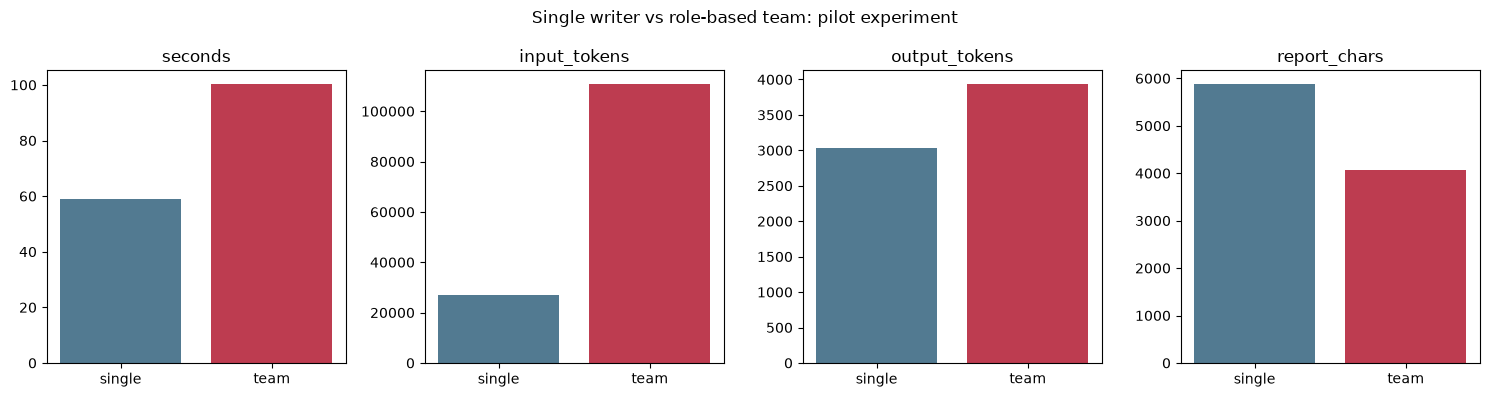

In [5]:
successful = results[results["status"] == "completed"].copy()
if successful.empty:
    print("성공한 조건이 없어 비교 그래프를 만들지 않습니다.")
else:
    metrics = ["seconds", "input_tokens", "output_tokens", "report_chars"]
    fig, axes = plt.subplots(1, 4, figsize=(15, 4))
    for ax, metric in zip(axes, metrics):
        if metric not in successful or successful[metric].isna().all():
            ax.text(0.5, 0.5, "Not reported", ha="center")
        else:
            values = successful.groupby("condition")[metric].mean()
            ax.bar(values.index, values.values, color=["#527a91", "#bd3c50"][:len(values)])
        ax.set_title(metric)
        ax.set_ylim(bottom=0)
    fig.suptitle("Single writer vs role-based team: pilot experiment")
    fig.tight_layout()
    plt.show()


## 7. 내용 품질 평가와 한계
자동 검사는 **필수 대제목 누락과 존재하지 않는 출처 ID**만 검사한다.
실제 출처 ID가 있어도 잘못된 주장일 수 있으므로 정확성 점수로 사용하지 않는다.
팀의 자체 검토 결과도 독립 평가가 아니다. 두 보고서는 각 조건 폴더의 `report.md`에 있다.

사람이 아래 기준으로 두 보고서를 원본과 대조해 평가한다. 아직 평가하지 않은 항목은 빈칸이다.
- 정확성(1~5): 주장이 제공 코드와 맞는가? 틀린 주장과 근거를 함께 기록.
- 구성(1~5): 필요한 내용과 설명 순서가 적절한가?
- 가독성(1~5): 초보자가 이해하기 쉬운가?
- 한계 표시(1~5): 코드 일부만 제공됐다는 점과 미실행 범위를 드러냈는가?

조건명을 가린 뒤 순서를 섞어 평가하면 선입견을 줄일 수 있다.


In [6]:
# 점수를 임의로 채우지 않습니다. 원문을 읽고 평가한 뒤 직접 입력하세요.
manual_scores = pd.DataFrame([
    {"condition": name, "accuracy": None, "structure": None,
     "readability": None, "limitations": None, "evidence_notes": "미평가"}
    for name in ["single", "team"]])
print(manual_scores.to_string(index=False))


condition accuracy structure readability limitations evidence_notes
   single     None      None        None        None            미평가
     team     None      None        None        None            미평가


## 8. 해석과 다음 실험
이번 결과는 조건당 1회인 예비 실험이다. 숫자를 확인하기 전 우열을 결론 내리지 않는다.
시간·사용량은 비교할 수 있지만, 독립적인 내용 품질 평가 전에는 역할 분담이 더 정확하다고 말할 수 없다.

다음 단계는 서로 다른 프로젝트 자료에서 조건당 3회 이상 반복하고 사람의 평가를 추가하는 것이다.
그다음 같은 작성 조건에서 모델만 바꾸는 비교를 별도로 진행한다.
로컬 LLM은 필수가 아니며, 실행 가능한 환경을 확보하면 같은 조건의 추가 비교 대상으로 넣을 수 있다.

### 재현 방법
프로젝트 폴더와 `runs`의 해당 실험 폴더를 함께 보관한다. 가상환경에 pandas와 matplotlib가 필요하다.
VS Code에서 노트북을 실행할 때는 해당 환경에 ipykernel을 설치하고 커널로 선택한다.
CLI 재실험: `python experiments/compare_reports.py --repeats 3`.
공유 시 기록 파일을 검토하고 인증정보·민감 자료가 포함되지 않았는지 확인한다.
